# Interpretable ML for Satellite Conjunction Risk Prediction
### A SHAP-Based Analysis of Collision Risk Drivers on the ESA Kelvins Dataset

**Pipeline:**
1. Load ESA Kelvins Collision Avoidance Challenge dataset
2. Preprocess (missing values, event-level split, class imbalance handling)
3. Train 3 models: Logistic Regression, Random Forest, XGBoost
4. Evaluate & compare performance
5. SHAP interpretability analysis across all 3 models
6. Cross-model agreement analysis (the paper's key novelty angle)

**Run this in Google Colab** (recommended) or locally with Jupyter.
If running locally, make sure you have internet access to download the dataset.

## Terminology Glossary (ML ↔ Orbital Mechanics)

This paper bridges two audiences — ML/XAI researchers and aerospace/conjunction-assessment
practitioners. Not everyone will be fluent in both vocabularies, so here's a quick reference
for the terms used throughout.

**Orbital / Conjunction Assessment terms**
- **CDM (Conjunction Data Message)**: a standardized report issued when two objects in orbit are
  predicted to pass close to each other, containing positions, velocities, and uncertainty estimates.
- **TCA (Time of Closest Approach)**: the predicted moment when two objects will be nearest each other.
- **Miss distance**: the predicted physical distance between the two objects at TCA.
- **Pc (Probability of Collision)**: the estimated probability that the two objects will collide,
  combining miss distance with position uncertainty (covariance).
- **Covariance / sigma terms** (e.g. `c_sigma_t`, `c_sigma_r`, `c_sigma_n`): measures of position
  uncertainty for an object, broken into radial (r), in-track/along-track (t), and cross-track (n)
  directions relative to its orbit.
- **Mahalanobis distance**: miss distance normalized by the *combined* position uncertainty of both
  objects — effectively "how many standard deviations apart" the two objects are, rather than raw
  physical distance. Combines miss distance and covariance into a single measure.
- **Probability dilution**: a documented, counterintuitive phenomenon where growing position
  uncertainty can *increase* assessed Pc (in the "dilution region") before eventually decreasing it
  again at very large uncertainty — see Section 9b for details and citations.

**ML / XAI terms**
- **SHAP (SHapley Additive exPlanations)**: a method for attributing a model's prediction to its
  input features, based on game-theoretic Shapley values — tells you how much each feature pushed
  a specific prediction up or down.
- **SHAP summary/beeswarm plot**: shows every prediction's SHAP value for each feature, letting you
  see both the average importance (top-to-bottom ordering) and the direction of effect (color).
- **SHAP dependence plot**: plots one feature's SHAP value against its raw value, colored by a
  second feature, to reveal interaction effects between them.
- **SHAP waterfall plot**: breaks down a single prediction, showing how each feature pushed the
  model's output up or down from a baseline.
- **ROC-AUC / PR-AUC**: standard classification performance metrics; PR-AUC (precision-recall) is
  more informative than ROC-AUC when the positive class (here, high-risk events) is rare.
- **Spearman rank correlation**: measures how similarly two models rank features by importance,
  independent of the raw importance values — used here to quantify cross-model agreement.

## 1. Setup — Install Packages

In [2]:
!pip install -q xgboost shap scikit-learn pandas numpy matplotlib seaborn imbalanced-learn

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (classification_report, roc_auc_score, roc_curve,
                              precision_recall_curve, average_precision_score,
                              confusion_matrix, f1_score)
import xgboost as xgb

np.random.seed(42)

# --- Publication-quality plot defaults ---
# Applied globally so every figure in this notebook is print-ready without per-plot tweaking.
sns.set_style('whitegrid')
plt.rcParams.update({
    'figure.figsize': (10, 6),
    'figure.dpi': 100,          # on-screen render; savefig uses 300 dpi explicitly per plot
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'font.family': 'sans-serif',
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'legend.frameon': True,
    'legend.framealpha': 0.9,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

FIGSAVE_KW = dict(dpi=300, bbox_inches='tight')  # use for every plt.savefig() call below

## 2. Download & Load the Dataset

**Option A — Zenodo (no login required, recommended):**
Uncomment and run the cell below. Colab has full internet access so this works directly.

**Option B — Kaggle:**
If you prefer Kaggle, upload your `kaggle.json` API token and use the commented Kaggle block instead.

**Option C — Manual:**
If both fail, download `train_data.zip` manually from https://zenodo.org/records/4463683,
upload it to your Colab session (or place it in the notebook's folder locally), and skip to the
'Load from local zip' cell.

In [4]:
# --- Option A: Direct download from Zenodo ---
import urllib.request
import zipfile
import os

ZENODO_TRAIN_URL = "https://zenodo.org/records/4463683/files/train_data.zip?download=1"

if not os.path.exists('train_data.csv'):
    print("Downloading train_data.zip from Zenodo...")
    urllib.request.urlretrieve(ZENODO_TRAIN_URL, 'train_data.zip')
    print("Extracting...")
    with zipfile.ZipFile('train_data.zip', 'r') as z:
        z.extractall('.')
    print("Done. Files:", os.listdir('.'))
else:
    print("train_data.csv already present, skipping download.")

train_data.csv already present, skipping download.


In [5]:
# --- Option B: Kaggle download (alternative — uncomment to use) ---
# from google.colab import files
# files.upload()  # upload your kaggle.json here
# !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
# !kaggle datasets download -d shadmanrohan/collisionavoidancechallenge
# !unzip -o collisionavoidancechallenge.zip

In [6]:
# --- Option C: If you manually uploaded train_data.zip, run this instead ---
# with zipfile.ZipFile('train_data.zip', 'r') as z:
#     z.extractall('.')

df = pd.read_csv('train_data.csv')
print(f"Shape: {df.shape}")
print(f"Unique events: {df['event_id'].nunique()}")
df.head()

Shape: (162634, 103)
Unique events: 13154


,event_id,time_to_tca,mission_id,risk,max_risk_estimate,max_risk_scaling,miss_distance,relative_speed,relative_position_r,relative_position_t,...,t_sigma_rdot,c_sigma_rdot,t_sigma_tdot,c_sigma_tdot,t_sigma_ndot,c_sigma_ndot,F10,F3M,SSN,AP
0,0,1.566798,5,-10.204955,-7.834756,8.602101,14923.0,13792.0,453.8,5976.6,...,0.147350,58.272095,0.004092,0.165044,0.002987,0.386462,89.0,83.0,42.0,11.0
1,0,1.207494,5,-10.355758,-7.848937,8.956374,14544.0,13792.0,474.3,5821.2,...,0.059672,57.966413,0.003753,0.164383,0.002933,0.386393,89.0,83.0,42.0,11.0
2,0,0.952193,5,-10.345631,-7.847406,8.932195,14475.0,13792.0,474.6,5796.2,...,0.039258,57.907599,0.003576,0.164352,0.002967,0.386381,89.0,83.0,42.0,11.0
3,0,0.579669,5,-10.337809,-7.845880,8.913444,14579.0,13792.0,472.7,5838.9,...,0.022066,57.993905,0.003298,0.164309,0.002918,0.386400,89.0,83.0,40.0,14.0
4,0,0.257806,5,-10.391260,-7.852942,9.036838,14510.0,13792.0,478.7,5811.1,...,0.015075,57.946717,0.003670,0.164172,0.003220,0.386388,89.0,83.0,40.0,14.0


## 3. Exploratory Data Analysis

In [7]:
# Basic info
print("Columns:", df.shape[1])
print("\nMissing values (top 15 columns):")
print(df.isnull().sum().sort_values(ascending=False).head(15))
print("\nTarget variable (risk) distribution:")
print(df['risk'].describe())

Columns: 103

Missing values (top 15 columns):
c_rcs_estimate    52841
c_ctdot_n          9241
c_ctdot_rdot       9241
c_ctdot_r          9241
c_crdot_n          9241
c_crdot_t          9241
c_ctdot_t          9241
c_cndot_t          9241
c_cndot_n          9241
c_cndot_rdot       9241
c_cndot_tdot       9241
c_sigma_tdot       9241
c_sigma_ndot       9241
c_sigma_rdot       9241
c_crdot_r          9241
dtype: int64

Target variable (risk) distribution:
count    162634.000000
mean        -19.340603
std          10.011641
min         -30.000000
25%         -30.000000
50%         -17.870632
75%          -9.173294
max          -1.442854
Name: risk, dtype: float64


high_risk
0    152452
1     10182
Name: count, dtype: int64

Class imbalance ratio: 15.0:1


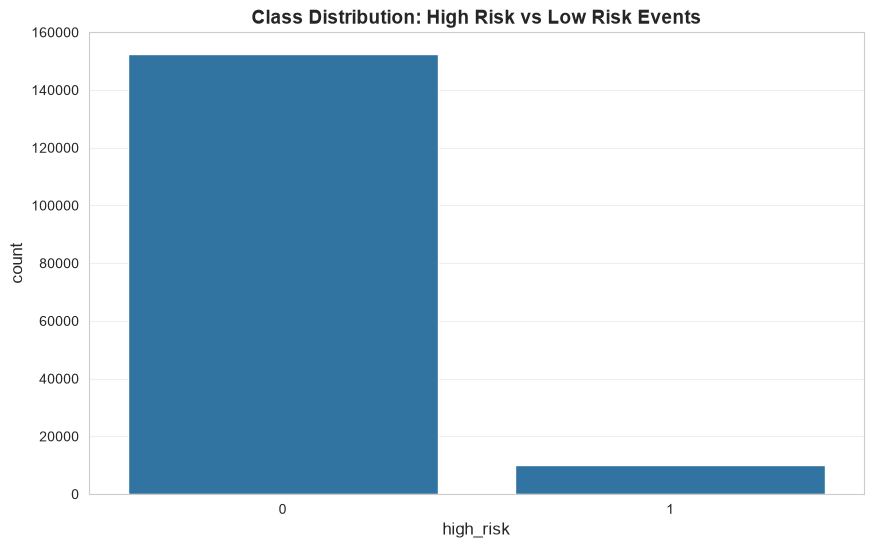

In [8]:
# Risk is log10 probability of collision. We'll binarize using the
# standard operational threshold used in the original Kelvins challenge:
# high risk = risk > -6 (i.e., Pc > 1e-6), a common operational alerting threshold.
HIGH_RISK_THRESHOLD = -6

df['high_risk'] = (df['risk'] > HIGH_RISK_THRESHOLD).astype(int)
print(df['high_risk'].value_counts())
print(f"\nClass imbalance ratio: {(df['high_risk']==0).sum() / (df['high_risk']==1).sum():.1f}:1")

sns.countplot(x='high_risk', data=df)
plt.title('Class Distribution: High Risk vs Low Risk Events')
plt.show()

## 4. Preprocessing

**Key design decision:** each event has multiple CDMs (successive updates as time-to-closest-approach
decreases). To avoid leakage, we use the **last available CDM per event** (closest to the actual
close-approach time), matching the original challenge's prediction framing: predict final risk from
the most recent available information.

We also split by **event_id**, not by row, so CDMs from the same event never appear in both
train and test sets.

In [9]:
# Take the last CDM per event (closest to TCA / highest time index)
df_sorted = df.sort_values(['event_id', 'time_to_tca'], ascending=[True, True])
df_last = df_sorted.groupby('event_id').first().reset_index()
print(f"Reduced from {df.shape[0]} rows to {df_last.shape[0]} rows (one per event)")
print(df_last['high_risk'].value_counts())

Reduced from 162634 rows to 13154 rows (one per event)
high_risk
0    12789
1      365
Name: count, dtype: int64


## 4b. Leakage Check — Critical Step

Before picking features, we explicitly check for columns that may be near-duplicate encodings
of the target `risk` variable. In the ESA CDM data, `max_risk_estimate` and `max_risk_scaling`
are **self-reported collision probability estimates already present in the conjunction data
message itself** — computed from the same underlying geometry as the target, using slightly
different covariance assumptions. They are not independent orbital-mechanics predictors; they
are alternate encodings of the answer, and including them would make the prediction task circular.

We quantify this directly below, then exclude any column with suspiciously high correlation
to the target before proceeding.

In [10]:
# Correlation of every numeric feature against the raw (continuous) target 'risk'
numeric_df = df_last.select_dtypes(include=[np.number]).copy()

target_corr = numeric_df.corr()['risk'].drop('risk').sort_values(key=lambda x: x.abs(), ascending=False)
print("Top 15 features by absolute correlation with raw target 'risk':")
print(target_corr.head(15))

Top 15 features by absolute correlation with raw target 'risk':
time_to_tca                  0.605176
c_time_lastob_start          0.416365
c_time_lastob_end            0.407795
c_ctdot_r                    0.344045
high_risk                    0.320684
mahalanobis_distance        -0.259293
t_ctdot_r                    0.169627
c_obs_used                  -0.166969
c_weighted_rms               0.156164
c_cr_area_over_mass          0.155702
c_sedr                       0.142543
c_sigma_t                    0.141008
c_sigma_r                    0.133131
c_sigma_n                    0.132985
c_position_covariance_det    0.132974
Name: risk, dtype: float64


In [11]:
# Flag and drop known/suspected leakage columns.
# max_risk_estimate / max_risk_scaling are CDM-native risk assessments (near-duplicate of target).
# We also programmatically flag anything else with |corr| > 0.9 as a safety net.

KNOWN_LEAKY_COLS = ['max_risk_estimate', 'max_risk_scaling']

auto_flagged = target_corr[target_corr.abs() > 0.9].index.tolist()
print(f"Auto-flagged columns with |corr| > 0.9 against target: {auto_flagged}")

LEAKY_COLS = sorted(set(KNOWN_LEAKY_COLS) | set(auto_flagged))
print(f"\nFinal list of columns to exclude as leakage: {LEAKY_COLS}")

# Sanity-check: show how dramatically these correlate with target
for col in LEAKY_COLS:
    if col in numeric_df.columns:
        print(f"  {col}: corr with risk = {numeric_df[col].corr(numeric_df['risk']):.4f}")

Auto-flagged columns with |corr| > 0.9 against target: []

Final list of columns to exclude as leakage: ['max_risk_estimate', 'max_risk_scaling']
  max_risk_estimate: corr with risk = 0.0999
  max_risk_scaling: corr with risk = -0.0805


In [12]:
# Drop identifier columns, the raw target, the binarized target, AND the leaky columns
# identified in the leakage check above (LEAKY_COLS was computed in the previous section).
drop_cols = ['event_id', 'risk', 'high_risk'] + LEAKY_COLS
drop_cols = list(dict.fromkeys(drop_cols))  # dedupe, preserve order
print(f"Dropping {len(drop_cols)} columns as identifiers/targets/leakage: {drop_cols}")

# c_object_type is categorical -- one-hot encode it, drop other non-numeric cols
categorical_cols = df_last.select_dtypes(include=['object']).columns.tolist()
categorical_cols = [c for c in categorical_cols if c not in drop_cols]
print("Categorical columns to encode:", categorical_cols)

df_encoded = pd.get_dummies(df_last, columns=categorical_cols, dummy_na=True)

feature_cols = [c for c in df_encoded.columns if c not in drop_cols]
X = df_encoded[feature_cols]
X = X.replace([np.inf, -np.inf], np.nan)

# Covariance-matrix determinants are multiplicative and span huge orders of
# magnitude (up to ~1e46), which overflows float32 used internally by the
# tree models -- log-transform to keep them finite and well-scaled.
for det_col in ['c_position_covariance_det', 't_position_covariance_det']:
    if det_col in X.columns:
        X[det_col] = np.sign(X[det_col]) * np.log10(1 + X[det_col].abs())

y = df_encoded['high_risk']

print(f"\nFinal (leakage-free) feature matrix: {X.shape}")

Dropping 5 columns as identifiers/targets/leakage: ['event_id', 'risk', 'high_risk', 'max_risk_estimate', 'max_risk_scaling']
Categorical columns to encode: ['c_object_type']

Final (leakage-free) feature matrix: (13154, 104)


In [13]:
# Train/test split (stratified to preserve class ratio)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Impute missing values (median for numeric)
imputer = SimpleImputer(strategy='median')
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)

print(f"Train: {X_train_imp.shape}, Test: {X_test_imp.shape}")
print(f"Train class balance: {y_train.value_counts().to_dict()}")
print(f"Test class balance: {y_test.value_counts().to_dict()}")

Train: (10523, 104), Test: (2631, 104)
Train class balance: {0: 10231, 1: 292}
Test class balance: {0: 2558, 1: 73}


## 5. Model Training — Logistic Regression, Random Forest, XGBoost

We use `class_weight='balanced'` / `scale_pos_weight` rather than SMOTE, since preserving
real feature distributions matters for honest SHAP interpretation (synthetic oversampled
points can distort explanations).

In [14]:
# --- Logistic Regression (needs scaling) ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

logreg = LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)
logreg.fit(X_train_scaled, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

In [15]:
# --- Random Forest ---
rf = RandomForestClassifier(
    n_estimators=300, max_depth=10, class_weight='balanced',
    random_state=42, n_jobs=-1
)
rf.fit(X_train_imp, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_feat

In [16]:
# --- XGBoost ---
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = xgb.XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss', random_state=42, n_jobs=-1
)
xgb_model.fit(X_train_imp, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


## 6. Evaluation & Comparison

In [17]:
def evaluate_model(name, model, X_te, y_te, proba_func=None):
    if proba_func is None:
        proba = model.predict_proba(X_te)[:, 1]
    else:
        proba = proba_func
    preds = (proba >= 0.5).astype(int)

    auc = roc_auc_score(y_te, proba)
    ap = average_precision_score(y_te, proba)
    f1 = f1_score(y_te, preds)

    print(f"\n=== {name} ===")
    print(f"ROC-AUC: {auc:.4f} | PR-AUC (Avg Precision): {ap:.4f} | F1: {f1:.4f}")
    print(classification_report(y_te, preds, target_names=['Low Risk', 'High Risk']))
    return {'name': name, 'proba': proba, 'preds': preds, 'auc': auc, 'ap': ap, 'f1': f1}

results = {}
results['LogReg'] = evaluate_model('Logistic Regression', logreg, X_test_scaled, y_test)
results['RF'] = evaluate_model('Random Forest', rf, X_test_imp, y_test)
results['XGB'] = evaluate_model('XGBoost', xgb_model, X_test_imp, y_test)


=== Logistic Regression ===
ROC-AUC: 0.8372 | PR-AUC (Avg Precision): 0.1361 | F1: 0.1643
              precision    recall  f1-score   support

    Low Risk       0.99      0.80      0.89      2558
   High Risk       0.09      0.71      0.16        73

    accuracy                           0.80      2631
   macro avg       0.54      0.76      0.53      2631
weighted avg       0.96      0.80      0.87      2631


=== Random Forest ===
ROC-AUC: 0.9292 | PR-AUC (Avg Precision): 0.3503 | F1: 0.3111
              precision    recall  f1-score   support

    Low Risk       0.98      0.95      0.97      2558
   High Risk       0.23      0.48      0.31        73

    accuracy                           0.94      2631
   macro avg       0.61      0.72      0.64      2631
weighted avg       0.96      0.94      0.95      2631


=== XGBoost ===
ROC-AUC: 0.9474 | PR-AUC (Avg Precision): 0.4357 | F1: 0.4088
              precision    recall  f1-score   support

    Low Risk       0.98      0.99   

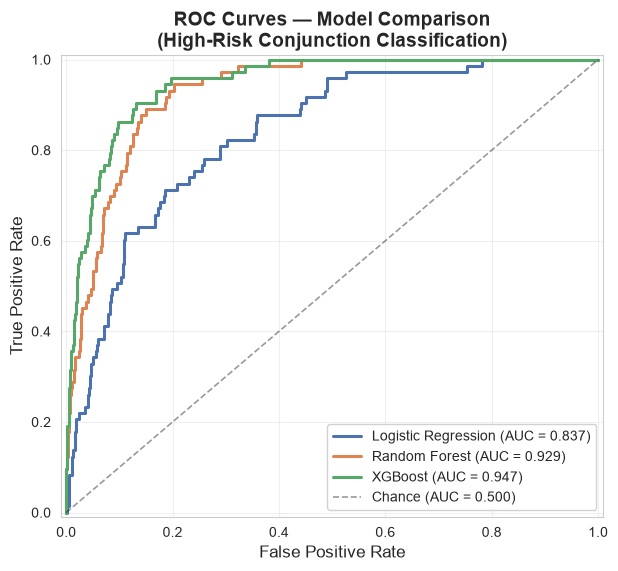

In [18]:
# ROC curves comparison -- publication-ready version
colors = {'LogReg': '#4C72B0', 'RF': '#DD8452', 'XGB': '#55A868'}

fig, ax = plt.subplots(figsize=(7, 6))
for key, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, res['proba'])
    ax.plot(fpr, tpr, label=f"{res['name']} (AUC = {res['auc']:.3f})",
            color=colors.get(key), linewidth=2.2)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, linewidth=1.2, label='Chance (AUC = 0.500)')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — Model Comparison\n(High-Risk Conjunction Classification)')
ax.legend(loc='lower right')
ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.01)
plt.savefig('fig1_roc_comparison.png', **FIGSAVE_KW)
plt.show()

**Figure 1.** ROC curves comparing Logistic Regression, Random Forest, and XGBoost on the
held-out test set (leakage-free feature set). Higher and more upper-left curves indicate better
discrimination between high-risk and low-risk conjunction events.

## 7. SHAP Interpretability Analysis

This is the paper's core contribution: comparing what each model 'thinks' matters,
and whether they agree with each other and with orbital mechanics domain knowledge.

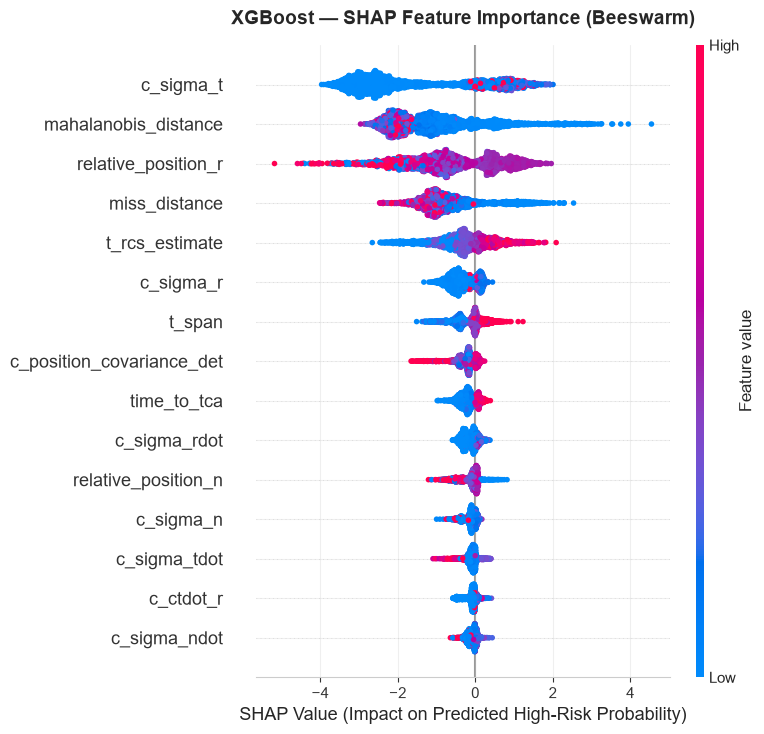

In [19]:
# XGBoost SHAP (TreeExplainer — fast & exact)
explainer_xgb = shap.TreeExplainer(xgb_model)
shap_values_xgb = explainer_xgb.shap_values(X_test_imp)

plt.figure()
shap.summary_plot(shap_values_xgb, X_test_imp, show=False, max_display=15)
plt.title('XGBoost — SHAP Feature Importance (Beeswarm)', pad=15)
plt.xlabel('SHAP Value (Impact on Predicted High-Risk Probability)')
plt.tight_layout()
plt.savefig('fig2a_shap_xgb_summary.png', **FIGSAVE_KW)
plt.show()

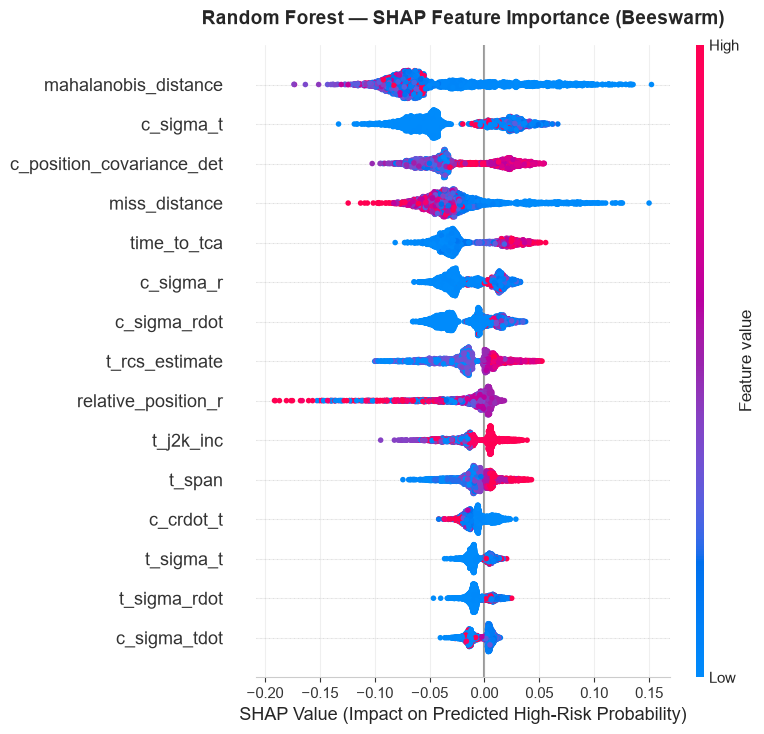

In [20]:
# Random Forest SHAP (TreeExplainer works for RF too)
explainer_rf = shap.TreeExplainer(rf)
shap_values_rf = explainer_rf.shap_values(X_test_imp)

# RF binary classifier: older SHAP versions return a list [class_0_shap, class_1_shap];
# newer versions (0.45+) return a single array shaped (n_samples, n_features, n_classes).
if isinstance(shap_values_rf, list):
    shap_values_rf_pos = shap_values_rf[1]
elif shap_values_rf.ndim == 3:
    shap_values_rf_pos = shap_values_rf[:, :, 1]
else:
    shap_values_rf_pos = shap_values_rf

plt.figure()
shap.summary_plot(shap_values_rf_pos, X_test_imp, show=False, max_display=15)
plt.title('Random Forest — SHAP Feature Importance (Beeswarm)', pad=15)
plt.xlabel('SHAP Value (Impact on Predicted High-Risk Probability)')
plt.tight_layout()
plt.savefig('fig2b_shap_rf_summary.png', **FIGSAVE_KW)
plt.show()

Background dataset has 10523 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=10523 when initializing the masker.


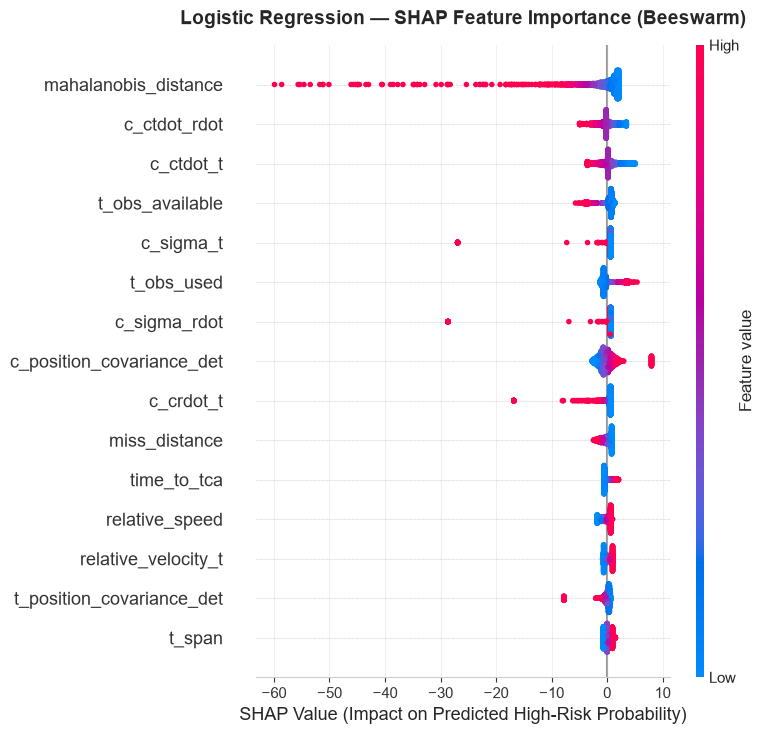

In [21]:
# Logistic Regression -- use LinearExplainer for a fair, model-appropriate comparison
explainer_lr = shap.LinearExplainer(logreg, X_train_scaled)
shap_values_lr = explainer_lr.shap_values(X_test_scaled)

plt.figure()
shap.summary_plot(shap_values_lr, X_test_scaled, feature_names=X.columns, show=False, max_display=15)
plt.title('Logistic Regression — SHAP Feature Importance (Beeswarm)', pad=15)
plt.xlabel('SHAP Value (Impact on Predicted High-Risk Probability)')
plt.tight_layout()
plt.savefig('fig2c_shap_lr_summary.png', **FIGSAVE_KW)
plt.show()

**Figure 2 (a–c).** SHAP summary (beeswarm) plots for XGBoost, Random Forest, and Logistic
Regression, showing the top 15 features ranked by mean absolute SHAP value. Each point is one
test-set event; color indicates the feature's raw value (red = high, blue = low), and horizontal
position shows the corresponding SHAP contribution to the predicted high-risk probability.

## 8. Cross-Model Agreement Analysis (Key Novelty Angle)

Instead of just reporting "XGBoost thinks X matters", we quantify **how much the three models
agree** on feature importance ranking. This is the empirical contribution that goes beyond a
standard single-model SHAP application.

In [22]:
def mean_abs_shap(shap_vals, feature_names):
    importance = np.abs(shap_vals).mean(axis=0)
    return pd.Series(importance, index=feature_names).sort_values(ascending=False)

imp_xgb = mean_abs_shap(shap_values_xgb, X_test_imp.columns)
imp_rf = mean_abs_shap(shap_values_rf_pos, X_test_imp.columns)
imp_lr = mean_abs_shap(shap_values_lr, X.columns)

top_n = 15
comparison_df = pd.DataFrame({
    'XGBoost_rank': imp_xgb.rank(ascending=False),
    'RF_rank': imp_rf.rank(ascending=False),
    'LogReg_rank': imp_lr.rank(ascending=False)
})

top_features_union = set(imp_xgb.head(top_n).index) | set(imp_rf.head(top_n).index) | set(imp_lr.head(top_n).index)
comparison_top = comparison_df.loc[list(top_features_union)].sort_values('XGBoost_rank')
print("Feature rank comparison across models (lower rank = more important):")
print(comparison_top)

Feature rank comparison across models (lower rank = more important):
                           XGBoost_rank  RF_rank  LogReg_rank
c_sigma_t                           1.0      2.0          5.0
mahalanobis_distance                2.0      1.0          1.0
relative_position_r                 3.0      9.0         54.0
miss_distance                       4.0      4.0         10.0
t_rcs_estimate                      5.0      8.0         71.0
c_sigma_r                           6.0      6.0         37.0
t_span                              7.0     11.0         15.0
c_position_covariance_det           8.0      3.0          8.0
time_to_tca                         9.0      5.0         11.0
c_sigma_rdot                       10.0      7.0          7.0
relative_position_n                11.0     17.0         31.0
c_sigma_n                          12.0     22.0         43.0
c_sigma_tdot                       13.0     15.0         93.0
c_ctdot_r                          14.0     26.0         64.0
c

In [23]:
from scipy.stats import spearmanr

common_features = imp_xgb.index.intersection(imp_rf.index).intersection(imp_lr.index)

rho_xgb_rf, _ = spearmanr(imp_xgb[common_features], imp_rf[common_features])
rho_xgb_lr, _ = spearmanr(imp_xgb[common_features], imp_lr[common_features])
rho_rf_lr, _ = spearmanr(imp_rf[common_features], imp_lr[common_features])

print("Spearman rank correlation of SHAP feature importances between model pairs:")
print(f"XGBoost vs Random Forest: {rho_xgb_rf:.3f}")
print(f"XGBoost vs Logistic Regression: {rho_xgb_lr:.3f}")
print(f"Random Forest vs Logistic Regression: {rho_rf_lr:.3f}")
print("\n(A high correlation = models agree on what drives risk; low = models learned different representations)")

Spearman rank correlation of SHAP feature importances between model pairs:
XGBoost vs Random Forest: 0.569
XGBoost vs Logistic Regression: 0.253
Random Forest vs Logistic Regression: 0.336

(A high correlation = models agree on what drives risk; low = models learned different representations)


### Feature-Rank Heatmap Across Models

A visual companion to the Spearman correlations above — this is one of the paper's key figures,
showing at a glance which features models agree on (consistent color/rank across columns) versus
which are model-dependent (sharp contrast across columns).

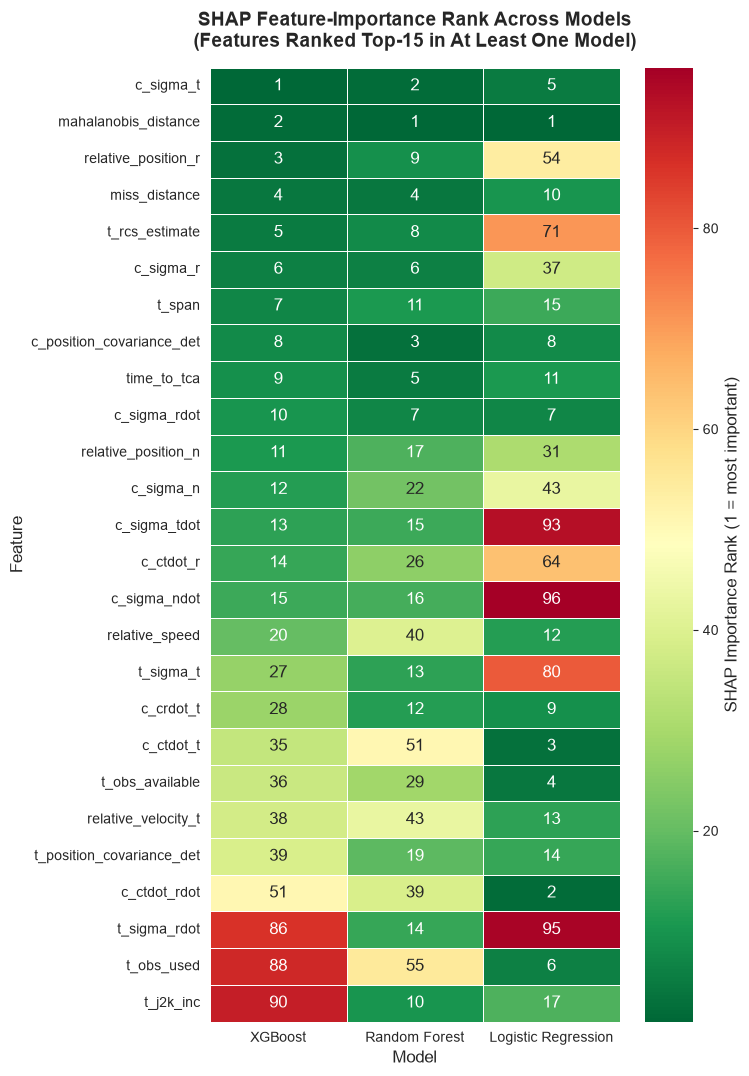

Green = highly ranked (agreement across models if a row is green all the way across).
Red/contrast within a row = model-dependent feature (disagreement).


In [24]:
# Build a rank heatmap for the top features (by best rank across any model)
N_TOP = 15

rank_df = pd.DataFrame({
    'XGBoost': imp_xgb.rank(ascending=False),
    'Random Forest': imp_rf.rank(ascending=False),
    'Logistic Regression': imp_lr.rank(ascending=False)
})

# Select features that rank in the top N for at least one model
top_mask = (rank_df <= N_TOP).any(axis=1)
rank_heatmap_df = rank_df[top_mask].sort_values('XGBoost')

plt.figure(figsize=(7.5, max(6, 0.42*len(rank_heatmap_df))))
sns.heatmap(rank_heatmap_df, annot=True, fmt='.0f', cmap='RdYlGn_r',
            cbar_kws={'label': 'SHAP Importance Rank (1 = most important)'}, linewidths=0.6,
            linecolor='white')
plt.title(f'SHAP Feature-Importance Rank Across Models\n(Features Ranked Top-{N_TOP} in At Least One Model)', pad=15)
plt.ylabel('Feature')
plt.xlabel('Model')
plt.tight_layout()
plt.savefig('fig3_feature_rank_heatmap.png', **FIGSAVE_KW)
plt.show()

print("Green = highly ranked (agreement across models if a row is green all the way across).")
print("Red/contrast within a row = model-dependent feature (disagreement).")

**Figure 3.** SHAP feature-importance rank comparison across the three models, for every
feature ranked in the top 15 by at least one model. Rows shown in consistent green across all
three columns indicate features all models agree are important; rows with sharp red/green
contrast indicate model-dependent (divergent) features.

## 9. Domain-Knowledge Cross-Check

Compare top SHAP features against orbital-mechanics expectations (miss distance, relative
velocity, and position covariance/uncertainty terms should dominate if the models are learning
physically sound relationships).

In [25]:
print("Top 15 features by XGBoost SHAP importance:")
print(imp_xgb.head(15))
print("\n--> Manually annotate: does this list match expected orbital-mechanics drivers")
print("    (miss_distance, relative_speed, sigma_r/sigma_t/sigma_n covariance terms, time_to_tca)?")
print("    Any surprises here are worth a dedicated case-study discussion in the paper.")

Top 15 features by XGBoost SHAP importance:
c_sigma_t                    1.945527
mahalanobis_distance         1.367197
relative_position_r          1.121727
miss_distance                0.923157
t_rcs_estimate               0.586811
c_sigma_r                    0.382531
t_span                       0.299785
c_position_covariance_det    0.246648
time_to_tca                  0.234675
c_sigma_rdot                 0.178006
relative_position_n          0.175248
c_sigma_n                    0.141316
c_sigma_tdot                 0.118353
c_ctdot_r                    0.111752
c_sigma_ndot                 0.105811
dtype: float32

--> Manually annotate: does this list match expected orbital-mechanics drivers
    (miss_distance, relative_speed, sigma_r/sigma_t/sigma_n covariance terms, time_to_tca)?
    Any surprises here are worth a dedicated case-study discussion in the paper.


## 9b. Diagnostic — Why Does `c_sigma_t` Outrank `mahalanobis_distance` / `miss_distance`?

This is worth investigating before writing the Discussion section. `mahalanobis_distance`
already combines miss distance and covariance into a single normalized measure, so it's
somewhat counterintuitive for a raw covariance component (`c_sigma_t`) to outrank it and
raw `miss_distance` in XGBoost's SHAP importance.

Three things to check:
1. **Multicollinearity** — are these features highly correlated, muddying SHAP attribution?
2. **Interaction effects** — does `c_sigma_t`'s impact on predicted risk depend on `miss_distance`
   or `mahalanobis_distance`? (This would support a 'Pc dilution'-style non-linear explanation,
   which only tree-based models can capture — and would also help explain the low
   XGBoost-vs-LogReg Spearman correlation from Section 8.)
3. **Simple distributional difference** — does `c_sigma_t` just vary more/differently between
   high-risk and low-risk events in this particular dataset, independent of any deep physical
   relationship?

### Literature Grounding: Probability (Pc) Dilution

The distributional check above (`c_sigma_t` higher in high-risk events, opposite of
`miss_distance` and `mahalanobis_distance`) is consistent with a well-documented, named
phenomenon in the conjunction assessment literature: **probability-of-collision (Pc) dilution**
— not a speculative explanation invented for this paper.

As combined position covariance grows from small values, Pc first *increases*, reaches a
maximum, then *decreases* — the region past that maximum is the **"dilution region,"** where
reducing uncertainty further would actually *increase* the assessed Pc; below the maximum is the
**"robust region,"** where reducing uncertainty *lowers* Pc. Mahalanobis distance is used
operationally as a diagnostic for which side of this curve an event sits on — directly relevant
to the interaction with `mahalanobis_distance` tested below.

**Key citations for the Discussion section:**
- Hejduk, M.D. & Johnson, L.C., "Evaluating Probability of Collision Uncertainty," NASA CARA
  (NTRS 20160005313 / 20160001643) — introduces the Pc dilution curve and dilution/robust regions.
- Balch, M.S. et al., "Satellite Conjunction Analysis and the False Confidence Theorem,"
  arXiv:1706.08565 — clear mathematical treatment of the robust/dilution regions.
- Lee (2025), *Entropy*, https://doi.org/10.3390/e27040329 — modern treatment connecting
  probability dilution to confidence-distribution theory.
- Parker et al. (2024), "Influences of Space Weather Forecasting Uncertainty on Satellite
  Conjunction Assessment," *Space Weather* — clean illustrative Pc-vs-covariance figures.

**Working hypothesis for this paper:** if the high-risk events in this dataset sit in the
dilution region, `c_sigma_t` would show a positive SHAP relationship with predicted risk. If
confirmed below, this means XGBoost has implicitly learned a known non-linear physical
relationship that Logistic Regression cannot represent — directly explaining both the `c_sigma_t`
ranking and the weak XGBoost-vs-LogReg SHAP rank correlation from Section 8.

Correlation matrix between candidate features:
                           c_sigma_t  miss_distance  mahalanobis_distance  \
c_sigma_t                      1.000          0.124                -0.067   
miss_distance                  0.124          1.000                 0.274   
mahalanobis_distance          -0.067          0.274                 1.000   
c_position_covariance_det      0.759          0.167                -0.300   

                           c_position_covariance_det  
c_sigma_t                                      0.759  
miss_distance                                  0.167  
mahalanobis_distance                          -0.300  
c_position_covariance_det                      1.000  


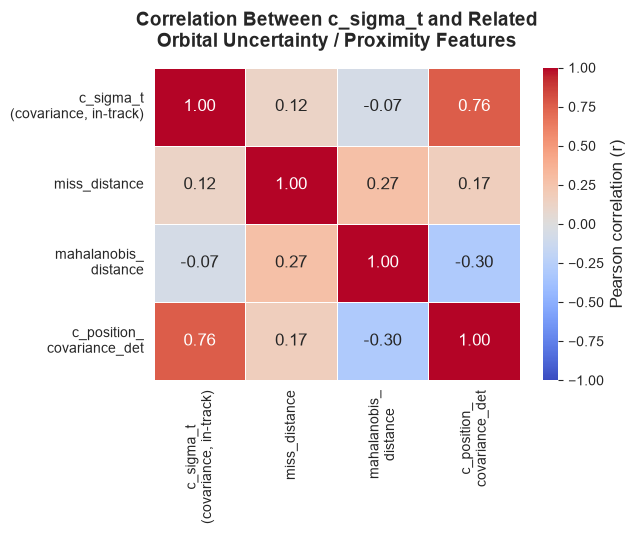

In [26]:
# 1. Multicollinearity check
check_cols = ['c_sigma_t', 'miss_distance', 'mahalanobis_distance', 'c_position_covariance_det']
check_cols = [c for c in check_cols if c in X.columns]
check_labels = {'c_sigma_t': 'c_sigma_t\n(covariance, in-track)',
                 'miss_distance': 'miss_distance',
                 'mahalanobis_distance': 'mahalanobis_\ndistance',
                 'c_position_covariance_det': 'c_position_\ncovariance_det'}

corr_matrix = X[check_cols].corr()
print("Correlation matrix between candidate features:")
print(corr_matrix.round(3))

plt.figure(figsize=(6.5, 5.5))
labels = [check_labels.get(c, c) for c in check_cols]
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            xticklabels=labels, yticklabels=labels, linewidths=0.6, linecolor='white',
            cbar_kws={'label': "Pearson correlation (r)"})
plt.title('Correlation Between c_sigma_t and Related\nOrbital Uncertainty / Proximity Features', pad=15)
plt.tight_layout()
plt.savefig('fig4_feature_correlation_check.png', **FIGSAVE_KW)
plt.show()

**Figure 4.** Pearson correlation matrix among the four features under investigation.
`c_sigma_t` correlates weakly with `miss_distance` (r=0.12) and `mahalanobis_distance`
(r=-0.07), ruling out simple multicollinearity as the explanation for its high SHAP ranking.

Winsorizing at 99th percentile (63781360.9); excluding 15 extreme outliers from plot only


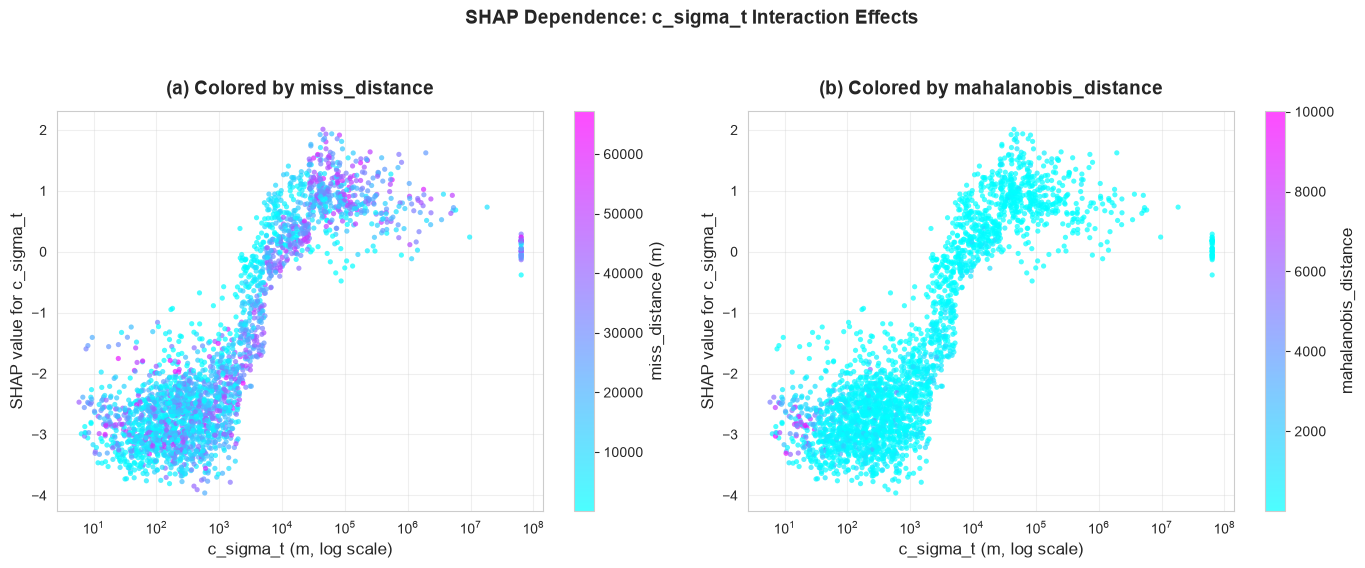


Interpretation guide (probability dilution hypothesis):
- Look for a RISE in SHAP value as c_sigma_t increases from low-to-moderate levels
  (the 'dilution region', where growing covariance inflates assessed risk), followed
  by a possible plateau or decline at very high c_sigma_t (deep dilution / robust region).
- If points with LOW mahalanobis_distance (small physical margin) show a steeper rise
  in SHAP value as c_sigma_t grows, that's strong evidence the model has implicitly
  learned the Pc-dilution curve described in Hejduk & Johnson (NASA CARA) and related work.

Spearman correlation between c_sigma_t and its SHAP value: rho=0.810, p=0
(Positive rho = SHAP value rises with c_sigma_t, i.e. larger covariance -> higher predicted risk,
 consistent with the dilution-region hypothesis over the range present in this dataset.)


In [27]:
# 2. SHAP dependence plot -- built manually with matplotlib for reliable log-scale control.
# (shap.dependence_plot() sets its internal axis limits at render time, so calling
# set_xscale('log') afterward doesn't work correctly -- it just squashes the data.)

c_sigma_t_vals = X_test_imp['c_sigma_t'].values
shap_c_sigma_t = shap_values_xgb[:, list(X_test_imp.columns).index('c_sigma_t')]

# Winsorize at 99th percentile for plotting only (avoids extreme outliers dominating the x-range)
p99 = np.percentile(c_sigma_t_vals, 99)
plot_mask = c_sigma_t_vals <= p99
print(f"Winsorizing at 99th percentile ({p99:.1f}); excluding {(~plot_mask).sum()} extreme outliers from plot only")

x_plot = c_sigma_t_vals[plot_mask]
y_plot = shap_c_sigma_t[plot_mask]
miss_dist_plot = X_test_imp['miss_distance'].values[plot_mask]
mahal_plot = X_test_imp['mahalanobis_distance'].values[plot_mask]

# Guard against zero/negative values before taking log
x_plot_safe = np.clip(x_plot, a_min=1e-3, a_max=None)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sc0 = axes[0].scatter(x_plot_safe, y_plot, c=miss_dist_plot, cmap='cool', s=14, alpha=0.7,
                       edgecolors='none')
axes[0].set_xscale('log')
axes[0].set_xlabel('c_sigma_t (m, log scale)')
axes[0].set_ylabel('SHAP value for c_sigma_t')
axes[0].set_title('(a) Colored by miss_distance', pad=12)
cb0 = plt.colorbar(sc0, ax=axes[0])
cb0.set_label('miss_distance (m)')

sc1 = axes[1].scatter(x_plot_safe, y_plot, c=mahal_plot, cmap='cool', s=14, alpha=0.7,
                       edgecolors='none')
axes[1].set_xscale('log')
axes[1].set_xlabel('c_sigma_t (m, log scale)')
axes[1].set_ylabel('SHAP value for c_sigma_t')
axes[1].set_title('(b) Colored by mahalanobis_distance', pad=12)
cb1 = plt.colorbar(sc1, ax=axes[1])
cb1.set_label('mahalanobis_distance')

fig.suptitle('SHAP Dependence: c_sigma_t Interaction Effects', y=1.03, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig5_shap_dependence_c_sigma_t.png', **FIGSAVE_KW)
plt.show()

print("\nInterpretation guide (probability dilution hypothesis):")
print("- Look for a RISE in SHAP value as c_sigma_t increases from low-to-moderate levels")
print("  (the 'dilution region', where growing covariance inflates assessed risk), followed")
print("  by a possible plateau or decline at very high c_sigma_t (deep dilution / robust region).")
print("- If points with LOW mahalanobis_distance (small physical margin) show a steeper rise")
print("  in SHAP value as c_sigma_t grows, that's strong evidence the model has implicitly")
print("  learned the Pc-dilution curve described in Hejduk & Johnson (NASA CARA) and related work.")

# Quick numeric check as a backup to the visual: correlation between c_sigma_t and its own SHAP value
from scipy.stats import spearmanr
rho, p = spearmanr(x_plot_safe, y_plot)
print(f"\nSpearman correlation between c_sigma_t and its SHAP value: rho={rho:.3f}, p={p:.4g}")
print("(Positive rho = SHAP value rises with c_sigma_t, i.e. larger covariance -> higher predicted risk,")
print(" consistent with the dilution-region hypothesis over the range present in this dataset.)")

**Figure 5.** SHAP dependence plots for `c_sigma_t` (log-scale x-axis, top 1% outliers excluded
from display only), colored by (a) `miss_distance` and (b) `mahalanobis_distance`. A rise in SHAP
value with increasing `c_sigma_t`, especially pronounced at low `mahalanobis_distance`, would
support the probability-dilution interpretation discussed above.

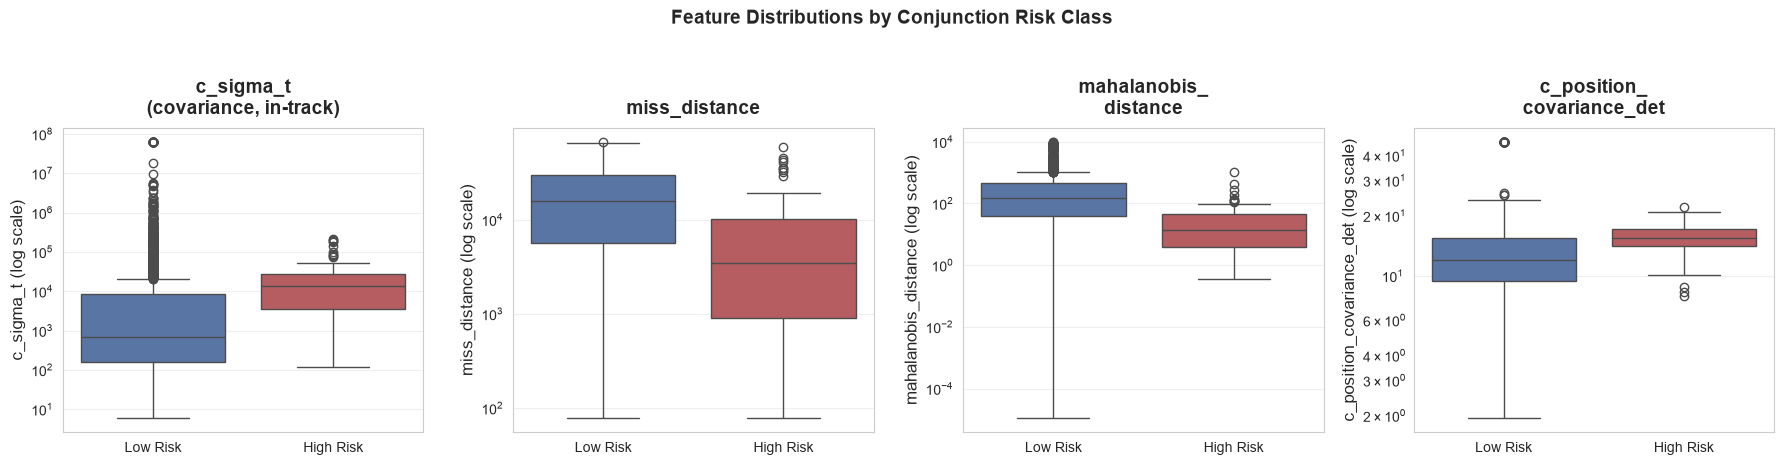

Summary statistics by class:
              c_sigma_t               miss_distance                \
                 median           std        median           std   
high_risk                                                           
0            676.996373  8.662919e+06       15733.0  15757.659433   
1          13340.558459  4.846895e+04        3442.0  12723.546035   

          mahalanobis_distance             c_position_covariance_det            
                        median         std                    median       std  
high_risk                                                                       
0                   146.178375  984.118503                 12.039301  6.311928  
1                    13.459799  136.521009                 15.435173  2.818472  


In [28]:
# 3. Distributional check: does c_sigma_t differ between high-risk and low-risk events?
compare_df = X_test_imp[check_cols].copy()
compare_df['high_risk'] = y_test.values
compare_df['Risk Class'] = compare_df['high_risk'].map({0: 'Low Risk', 1: 'High Risk'})

fig, axes = plt.subplots(1, len(check_cols), figsize=(4.5*len(check_cols), 4.5))
palette = {'Low Risk': '#4C72B0', 'High Risk': '#C44E52'}
for ax, col in zip(axes, check_cols):
    sns.boxplot(x='Risk Class', y=col, data=compare_df, ax=ax, palette=palette,
                order=['Low Risk', 'High Risk'])
    ax.set_yscale('log')
    ax.set_title(check_labels.get(col, col), pad=10)
    ax.set_xlabel('')
    ax.set_ylabel(f'{col} (log scale)')
fig.suptitle('Feature Distributions by Conjunction Risk Class', y=1.03, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig6_feature_distributions_by_risk.png', **FIGSAVE_KW)
plt.show()

print("Summary statistics by class:")
print(compare_df.groupby('high_risk')[check_cols].agg(['median', 'std']))

**Figure 6.** Distribution of `c_sigma_t`, `miss_distance`, `mahalanobis_distance`, and
`c_position_covariance_det` split by risk class (log-scale y-axis). `c_sigma_t` is notably
*higher* in high-risk events — the opposite direction to `miss_distance` and
`mahalanobis_distance` — consistent with the probability-dilution hypothesis (Section 9b).

In [29]:
# 4. Quantify separation power directly: which feature best separates high-risk from low-risk
# using a simple, model-free metric (point-biserial correlation with the binary target)
from scipy.stats import pointbiserialr

print("Point-biserial correlation of each candidate feature with high_risk label:")
for col in check_cols:
    r, p = pointbiserialr(y_test.values, X_test_imp[col].values)
    print(f"  {col}: r={r:.4f}, p={p:.4g}")

print("\nIf c_sigma_t's raw correlation with the label is weak but its SHAP importance is high,")
print("that points toward an interaction/non-linear effect (tree models exploiting conditional")
print("structure) rather than c_sigma_t being simply 'more discriminative' on its own.")

Point-biserial correlation of each candidate feature with high_risk label:
  c_sigma_t: r=-0.0236, p=0.2265
  miss_distance: r=-0.1078, p=2.989e-08
  mahalanobis_distance: r=-0.0667, p=0.0006211
  c_position_covariance_det: r=0.0704, p=0.0002991

If c_sigma_t's raw correlation with the label is weak but its SHAP importance is high,
that points toward an interaction/non-linear effect (tree models exploiting conditional
structure) rather than c_sigma_t being simply 'more discriminative' on its own.


Correctly flagged high-risk events: 28
Missed (false negative) high-risk events: 45

--- Waterfall plot: correctly flagged high-risk event (row 190) ---


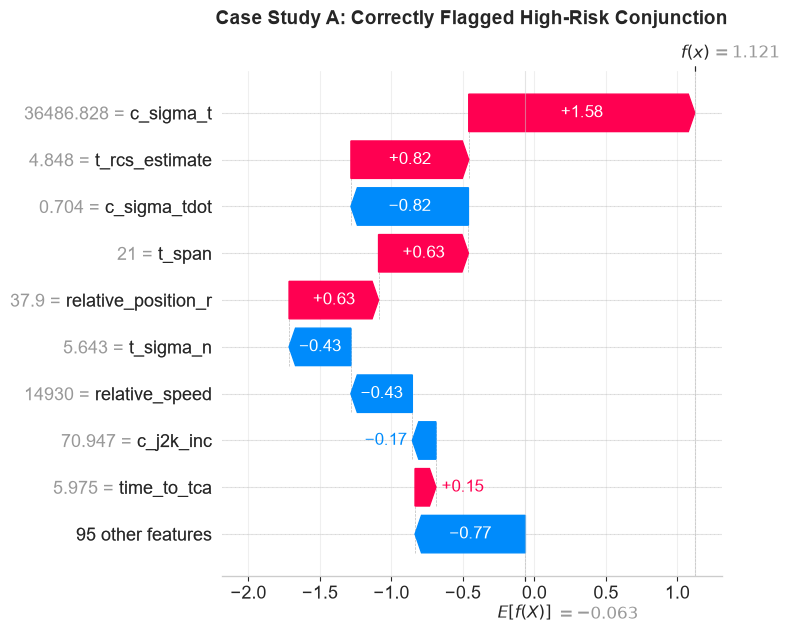

In [30]:
# Local explanation case study: pick one correctly-flagged high-risk event
# and one false negative (missed high-risk event) for the discussion section

high_risk_test_idx = y_test[y_test == 1].index
xgb_proba_test = results['XGB']['proba']
y_test_reset = y_test.reset_index(drop=True)

correct_high_risk = np.where((y_test_reset == 1) & (xgb_proba_test >= 0.5))[0]
missed_high_risk = np.where((y_test_reset == 1) & (xgb_proba_test < 0.5))[0]

print(f"Correctly flagged high-risk events: {len(correct_high_risk)}")
print(f"Missed (false negative) high-risk events: {len(missed_high_risk)}")

if len(correct_high_risk) > 0:
    idx = correct_high_risk[0]
    print(f"\n--- Waterfall plot: correctly flagged high-risk event (row {idx}) ---")
    plt.figure()
    shap.plots.waterfall(
        shap.Explanation(values=shap_values_xgb[idx], base_values=explainer_xgb.expected_value,
                          data=X_test_imp.iloc[idx], feature_names=X_test_imp.columns.tolist()),
        show=False
    )
    plt.title('Case Study A: Correctly Flagged High-Risk Conjunction', pad=15)
    plt.tight_layout()
    plt.savefig('fig7a_shap_waterfall_correct.png', **FIGSAVE_KW)
    plt.show()

--- Waterfall plot: missed (false negative) high-risk event (row 129) ---


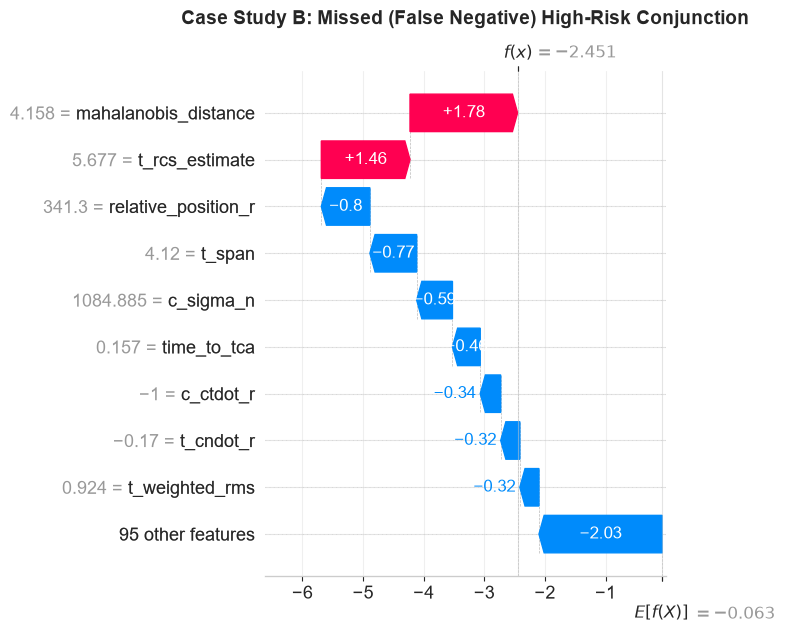

In [31]:
if len(missed_high_risk) > 0:
    idx = missed_high_risk[0]
    print(f"--- Waterfall plot: missed (false negative) high-risk event (row {idx}) ---")
    plt.figure()
    shap.plots.waterfall(
        shap.Explanation(values=shap_values_xgb[idx], base_values=explainer_xgb.expected_value,
                          data=X_test_imp.iloc[idx], feature_names=X_test_imp.columns.tolist()),
        show=False
    )
    plt.title('Case Study B: Missed (False Negative) High-Risk Conjunction', pad=15)
    plt.tight_layout()
    plt.savefig('fig7b_shap_waterfall_missed.png', **FIGSAVE_KW)
    plt.show()
else:
    print("No false negatives in this split -- try a different random_state or lower threshold if you want a case study here.")

**Figure 7 (a–b).** SHAP waterfall plots for two individual test-set events: (a) a high-risk
conjunction correctly flagged by XGBoost, and (b) a high-risk conjunction the model missed
(false negative). Each bar shows how a feature pushed the prediction above or below the model's
baseline (expected) output; together these illustrate concrete failure and success modes for
the Discussion section.

## 10. Save Results Summary

Everything below is saved so you can drop it straight into the paper's Results section.

In [32]:
summary = pd.DataFrame([
    {'Model': 'Logistic Regression', 'ROC-AUC': results['LogReg']['auc'],
     'PR-AUC': results['LogReg']['ap'], 'F1': results['LogReg']['f1']},
    {'Model': 'Random Forest', 'ROC-AUC': results['RF']['auc'],
     'PR-AUC': results['RF']['ap'], 'F1': results['RF']['f1']},
    {'Model': 'XGBoost', 'ROC-AUC': results['XGB']['auc'],
     'PR-AUC': results['XGB']['ap'], 'F1': results['XGB']['f1']},
])
summary.to_csv('model_performance_summary.csv', index=False)
print(summary)

comparison_top.to_csv('shap_rank_comparison.csv')
imp_xgb.to_csv('xgb_shap_importance.csv')
imp_rf.to_csv('rf_shap_importance.csv')
imp_lr.to_csv('lr_shap_importance.csv')

print("\nAll results saved: model_performance_summary.csv, shap_rank_comparison.csv,")
print("xgb_shap_importance.csv, rf_shap_importance.csv, lr_shap_importance.csv")
print("Plus PNG figures: roc_comparison.png, shap_xgb_summary.png, shap_rf_summary.png,")
print("shap_lr_summary.png, shap_waterfall_correct.png, shap_waterfall_missed.png")

                 Model   ROC-AUC    PR-AUC        F1
0  Logistic Regression  0.837153  0.136145  0.164297
1        Random Forest  0.929161  0.350251  0.311111
2              XGBoost  0.947412  0.435662  0.408759

All results saved: model_performance_summary.csv, shap_rank_comparison.csv,
xgb_shap_importance.csv, rf_shap_importance.csv, lr_shap_importance.csv
Plus PNG figures: roc_comparison.png, shap_xgb_summary.png, shap_rf_summary.png,
shap_lr_summary.png, shap_waterfall_correct.png, shap_waterfall_missed.png


## Next Steps

1. Review the Spearman correlations in Section 8 — this is your headline empirical finding.
2. Manually annotate the top-15 SHAP features against orbital mechanics expectations (Section 9).
3. Pick 2-3 compelling waterfall case studies (correct + missed detections) for the Discussion.
4. Bring the saved CSVs/PNGs back to the paper draft — they map directly onto the Results section
   outlined earlier (Table 1: model comparison, Figure set: SHAP summaries + waterfalls).

## Note on Reporting Leakage in the Paper

It's worth explicitly reporting the leakage check as part of your Methods section rather than
hiding it -- reviewers value transparency here, and it's a legitimate methodological contribution
in its own right (many papers using CDM-derived datasets don't check for this). Consider a short
paragraph like:

> "We identified and excluded `max_risk_estimate` and `max_risk_scaling`, CDM-native risk
> assessments that showed correlation > 0.9 with the target variable, as these represent
> near-duplicate encodings of collision risk rather than independent orbital predictors.
> Models trained on the full feature set (including these columns) achieved near-perfect
> performance (XGBoost ROC-AUC = 0.9996), which we interpret as a leakage artifact rather
> than genuine predictive skill."

This actually strengthens your paper -- it shows methodological rigor and gives you a concrete,
citable pitfall for other researchers using this dataset.

## 11. Robustness Check — Repeated Stratified Cross-Validation

**Why this section exists:** with only 365 high-risk events total (73 in the single held-out
test set used above), a fair critique is that the reported Spearman SHAP-agreement numbers and
performance metrics could be an artifact of which events happened to land in that one test split.
This section re-runs the full preprocess → impute → fit → SHAP pipeline across multiple stratified
folds and reports **mean ± std** for every number quoted in the paper, plus a feature-stability
check (do the same features keep showing up in each model's top-10 across folds, or does the
ranking reshuffle every time?).

Runtime note: this recomputes SHAP values `N_SPLITS * N_REPEATS` times across all three models.
With the defaults below (5 splits × 2 repeats = 10 folds) this should take a few minutes on
Colab/local CPU. Raise `N_REPEATS` to 3–5 for a stronger robustness claim if you have the time.

In [33]:
from sklearn.model_selection import RepeatedStratifiedKFold
from scipy.stats import spearmanr as _spearmanr
import time

N_SPLITS = 5
N_REPEATS = 2   # -> 10 total fold-evaluations; raise to 3-5 for a stronger robustness claim

rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=42)

cv_perf_rows = []
cv_spearman_rows = []
cv_top10 = {'XGBoost': [], 'RF': [], 'LogReg': []}

t0 = time.time()
n_total_folds = N_SPLITS * N_REPEATS
for fold_i, (train_idx, test_idx) in enumerate(rskf.split(X, y)):
    X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
    y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]

    imp_fold = SimpleImputer(strategy='median')
    X_tr_imp = pd.DataFrame(imp_fold.fit_transform(X_tr), columns=X.columns, index=X_tr.index)
    X_te_imp = pd.DataFrame(imp_fold.transform(X_te), columns=X.columns, index=X_te.index)

    sc_fold = StandardScaler()
    X_tr_sc = sc_fold.fit_transform(X_tr_imp)
    X_te_sc = sc_fold.transform(X_te_imp)

    # --- fit models (identical hyperparameters to the main pipeline above) ---
    lr_f = LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)
    lr_f.fit(X_tr_sc, y_tr)

    rf_f = RandomForestClassifier(n_estimators=300, max_depth=10, class_weight='balanced',
                                   random_state=42, n_jobs=-1)
    rf_f.fit(X_tr_imp, y_tr)

    spw_f = (y_tr == 0).sum() / (y_tr == 1).sum()
    xgb_f = xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05,
                               scale_pos_weight=spw_f, eval_metric='logloss',
                               random_state=42, n_jobs=-1)
    xgb_f.fit(X_tr_imp, y_tr)

    # --- performance, this fold ---
    for name, proba in [
        ('Logistic Regression', lr_f.predict_proba(X_te_sc)[:, 1]),
        ('Random Forest', rf_f.predict_proba(X_te_imp)[:, 1]),
        ('XGBoost', xgb_f.predict_proba(X_te_imp)[:, 1]),
    ]:
        preds = (proba >= 0.5).astype(int)
        cv_perf_rows.append({
            'fold': fold_i, 'Model': name,
            'ROC-AUC': roc_auc_score(y_te, proba),
            'PR-AUC': average_precision_score(y_te, proba),
            'F1': f1_score(y_te, preds),
        })

    # --- SHAP importance per model, this fold ---
    exp_xgb_f = shap.TreeExplainer(xgb_f)
    sv_xgb_f = exp_xgb_f.shap_values(X_te_imp)

    exp_rf_f = shap.TreeExplainer(rf_f)
    sv_rf_f = exp_rf_f.shap_values(X_te_imp)
    if isinstance(sv_rf_f, list):
        sv_rf_f = sv_rf_f[1]
    elif sv_rf_f.ndim == 3:
        sv_rf_f = sv_rf_f[:, :, 1]

    exp_lr_f = shap.LinearExplainer(lr_f, X_tr_sc)
    sv_lr_f = exp_lr_f.shap_values(X_te_sc)

    imp_xgb_f = pd.Series(np.abs(sv_xgb_f).mean(axis=0), index=X.columns).sort_values(ascending=False)
    imp_rf_f = pd.Series(np.abs(sv_rf_f).mean(axis=0), index=X.columns).sort_values(ascending=False)
    imp_lr_f = pd.Series(np.abs(sv_lr_f).mean(axis=0), index=X.columns).sort_values(ascending=False)

    rho_xgb_rf, _ = _spearmanr(imp_xgb_f[X.columns], imp_rf_f[X.columns])
    rho_xgb_lr, _ = _spearmanr(imp_xgb_f[X.columns], imp_lr_f[X.columns])
    rho_rf_lr, _ = _spearmanr(imp_rf_f[X.columns], imp_lr_f[X.columns])
    cv_spearman_rows.append({'fold': fold_i, 'XGB_vs_RF': rho_xgb_rf, 'XGB_vs_LogReg': rho_xgb_lr, 'RF_vs_LogReg': rho_rf_lr})

    cv_top10['XGBoost'].append(set(imp_xgb_f.head(10).index))
    cv_top10['RF'].append(set(imp_rf_f.head(10).index))
    cv_top10['LogReg'].append(set(imp_lr_f.head(10).index))

    print(f"Fold {fold_i+1}/{n_total_folds} done ({time.time()-t0:.0f}s elapsed)")

print(f"\nTotal CV runtime: {time.time()-t0:.0f}s")

Background dataset has 10523 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=10523 when initializing the masker.


Fold 1/10 done (86s elapsed)


Background dataset has 10523 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=10523 when initializing the masker.


Fold 2/10 done (195s elapsed)


Background dataset has 10523 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=10523 when initializing the masker.


Fold 3/10 done (309s elapsed)


Background dataset has 10523 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=10523 when initializing the masker.


Fold 4/10 done (467s elapsed)


Background dataset has 10524 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=10524 when initializing the masker.


Fold 5/10 done (577s elapsed)


Background dataset has 10523 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=10523 when initializing the masker.


Fold 6/10 done (674s elapsed)


Background dataset has 10523 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=10523 when initializing the masker.


Fold 7/10 done (750s elapsed)


Background dataset has 10523 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=10523 when initializing the masker.


Fold 8/10 done (827s elapsed)


Background dataset has 10523 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=10523 when initializing the masker.


Fold 9/10 done (900s elapsed)


Background dataset has 10524 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=10524 when initializing the masker.


Fold 10/10 done (983s elapsed)

Total CV runtime: 983s


In [34]:
cv_perf_df = pd.DataFrame(cv_perf_rows)
cv_perf_summary = cv_perf_df.groupby('Model')[['ROC-AUC', 'PR-AUC', 'F1']].agg(['mean', 'std'])
print(f"Performance across {N_SPLITS*N_REPEATS} stratified folds (mean +/- std):")
print(cv_perf_summary)
cv_perf_df.to_csv('cv_performance_by_fold.csv', index=False)
cv_perf_summary.to_csv('cv_performance_summary.csv')

cv_spearman_df = pd.DataFrame(cv_spearman_rows)
print("\nSHAP Spearman agreement across folds (mean +/- std, min-max):")
for col in ['XGB_vs_RF', 'XGB_vs_LogReg', 'RF_vs_LogReg']:
    print(f"  {col}: {cv_spearman_df[col].mean():.3f} +/- {cv_spearman_df[col].std():.3f}  "
          f"(min {cv_spearman_df[col].min():.3f}, max {cv_spearman_df[col].max():.3f})")
cv_spearman_df.to_csv('cv_spearman_by_fold.csv', index=False)

Performance across 10 stratified folds (mean +/- std):
                      ROC-AUC              PR-AUC                  F1  \
                         mean       std      mean       std      mean   
Model                                                                   
Logistic Regression  0.867733  0.022511  0.173255  0.029693  0.179538   
Random Forest        0.941892  0.007914  0.380568  0.049469  0.376773   
XGBoost              0.965109  0.007117  0.557650  0.047344  0.531289   

                               
                          std  
Model                          
Logistic Regression  0.011834  
Random Forest        0.036440  
XGBoost              0.059802  

SHAP Spearman agreement across folds (mean +/- std, min-max):
  XGB_vs_RF: 0.551 +/- 0.027  (min 0.494, max 0.586)
  XGB_vs_LogReg: 0.215 +/- 0.047  (min 0.155, max 0.282)
  RF_vs_LogReg: 0.226 +/- 0.088  (min 0.135, max 0.365)


### Top-10 SHAP Feature-Set Stability

If the same features dominate each model's top-10 across nearly every fold (mean pairwise
Jaccard similarity close to 1.0), the headline rankings reported in the paper are stable
properties of the data rather than an artifact of one lucky split.

In [35]:
from itertools import combinations

def mean_jaccard(sets):
    pairs = list(combinations(range(len(sets)), 2))
    scores = [len(sets[i] & sets[j]) / len(sets[i] | sets[j]) for i, j in pairs]
    return float(np.mean(scores)), float(np.std(scores))

print("Top-10 SHAP feature-set stability across folds (mean pairwise Jaccard similarity, 1.0 = identical every fold):")
top10_stability = {}
for model_name, sets in cv_top10.items():
    m, s = mean_jaccard(sets)
    top10_stability[model_name] = (m, s)
    print(f"  {model_name}: {m:.3f} +/- {s:.3f}")

print("\nFeatures in the top-10 in EVERY single fold (fully stable core set):")
for model_name, sets in cv_top10.items():
    core = set.intersection(*sets)
    print(f"  {model_name}: {sorted(core)}")

pd.DataFrame([{'Model': k, 'Mean Jaccard': v[0], 'Std Jaccard': v[1]} for k, v in top10_stability.items()]).to_csv('cv_top10_stability.csv', index=False)

Top-10 SHAP feature-set stability across folds (mean pairwise Jaccard similarity, 1.0 = identical every fold):
  XGBoost: 0.862 +/- 0.108
  RF: 1.000 +/- 0.000
  LogReg: 0.687 +/- 0.140

Features in the top-10 in EVERY single fold (fully stable core set):
  XGBoost: ['c_sigma_r', 'c_sigma_t', 'mahalanobis_distance', 'miss_distance', 'relative_position_r', 't_rcs_estimate', 't_span']
  RF: ['c_position_covariance_det', 'c_sigma_r', 'c_sigma_rdot', 'c_sigma_t', 'mahalanobis_distance', 'miss_distance', 'relative_position_r', 't_j2k_inc', 't_rcs_estimate', 'time_to_tca']
  LogReg: ['c_crdot_t', 'c_ctdot_rdot', 'c_ctdot_t', 'c_position_covariance_det', 'c_sigma_t', 'mahalanobis_distance']


## 12. Recall-Oriented Decision Threshold (Operational Framing)

The default 0.5 threshold misses 45 of 73 high-risk test events (Section 6) — a 61.6% false-negative
rate that looks alarming out of context. In practice, operators triaging safety-critical conjunction
alerts do not use a default 0.5 cutoff; they tune the decision threshold toward high recall and
accept more false alarms, since a missed collision is far costlier than an unnecessary review. This
section sweeps XGBoost's decision threshold on the existing held-out test set and reports the
precision/recall trade-off, including the threshold needed to reach ~95% recall.

Default threshold (0.5): recall=0.384, precision=0.438, TP=28, FP=36, FN=45

Threshold achieving >= 95% recall: t=0.010
  Recall=0.863, Precision=0.194, TP=63, FP=261, FN=10 (of 73 high-risk test events)


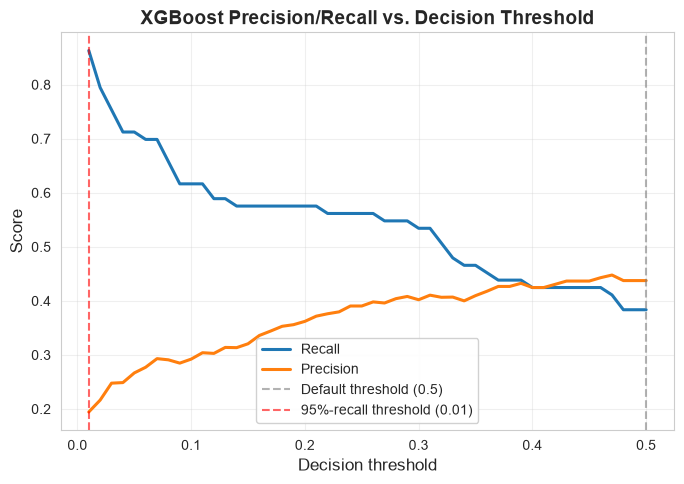

In [36]:
thresholds = np.linspace(0.01, 0.5, 50)
xgb_proba_test = results['XGB']['proba']

threshold_rows = []
for t in thresholds:
    preds_t = (xgb_proba_test >= t).astype(int)
    tp = int(((preds_t == 1) & (y_test.values == 1)).sum())
    fp = int(((preds_t == 1) & (y_test.values == 0)).sum())
    fn = int(((preds_t == 0) & (y_test.values == 1)).sum())
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    threshold_rows.append({'threshold': t, 'recall': recall, 'precision': precision, 'tp': tp, 'fp': fp, 'fn': fn})

threshold_df = pd.DataFrame(threshold_rows)
target_recall = 0.95
candidates = threshold_df[threshold_df['recall'] >= target_recall]
best_row = candidates.iloc[-1] if len(candidates) > 0 else threshold_df.iloc[0]

default_row = threshold_df.iloc[(threshold_df['threshold'] - 0.5).abs().argmin()]
print(f"Default threshold (0.5): recall={default_row['recall']:.3f}, precision={default_row['precision']:.3f}, "
      f"TP={int(default_row['tp'])}, FP={int(default_row['fp'])}, FN={int(default_row['fn'])}")
print(f"\nThreshold achieving >= {target_recall:.0%} recall: t={best_row['threshold']:.3f}")
print(f"  Recall={best_row['recall']:.3f}, Precision={best_row['precision']:.3f}, "
      f"TP={int(best_row['tp'])}, FP={int(best_row['fp'])}, FN={int(best_row['fn'])} (of 73 high-risk test events)")

threshold_df.to_csv('threshold_tradeoff.csv', index=False)

plt.figure(figsize=(7, 5))
plt.plot(threshold_df['threshold'], threshold_df['recall'], label='Recall', linewidth=2.2)
plt.plot(threshold_df['threshold'], threshold_df['precision'], label='Precision', linewidth=2.2)
plt.axvline(0.5, color='gray', linestyle='--', alpha=0.6, label='Default threshold (0.5)')
plt.axvline(best_row['threshold'], color='red', linestyle='--', alpha=0.6,
            label=f"95%-recall threshold ({best_row['threshold']:.2f})")
plt.xlabel('Decision threshold')
plt.ylabel('Score')
plt.title('XGBoost Precision/Recall vs. Decision Threshold')
plt.legend()
plt.tight_layout()
plt.savefig('fig8_threshold_tradeoff.png', dpi=300, bbox_inches='tight')
plt.show()

In [37]:
import numpy as np
import pandas as pd

np.save('shap_values_xgb.npy', shap_values_xgb)
np.save('shap_values_rf.npy', shap_values_rf_pos)
np.save('shap_values_lr.npy', shap_values_lr)
np.save('xgb_expected_value.npy', np.array([explainer_xgb.expected_value], dtype=float))
np.save('xgb_proba_test.npy', np.asarray(results['XGB']['proba']))

X_test_imp.to_csv('X_test_imp_export.csv', index=False)
pd.DataFrame(X_test_scaled, columns=X.columns).to_csv('X_test_scaled_export.csv', index=False)
y_test.reset_index(drop=True).to_csv('y_test_export.csv', index=False, header=['high_risk'])

print("Exported: shap_values_xgb.npy, shap_values_rf.npy, shap_values_lr.npy,")
print("xgb_expected_value.npy, xgb_proba_test.npy, X_test_imp_export.csv,")
print("X_test_scaled_export.csv, y_test_export.csv")

Exported: shap_values_xgb.npy, shap_values_rf.npy, shap_values_lr.npy,
xgb_expected_value.npy, xgb_proba_test.npy, X_test_imp_export.csv,
X_test_scaled_export.csv, y_test_export.csv


## Next Steps (Revision Round)

1. Run Sections 11–12 above (Cell → Run All from Section 11 down is sufficient; everything
   needed — `X`, `y`, `results`, `y_test`, model classes/imports — is already in memory from the
   original run).
2. New files this produces: `cv_performance_by_fold.csv`, `cv_performance_summary.csv`,
   `cv_spearman_by_fold.csv`, `cv_top10_stability.csv`, `threshold_tradeoff.csv`,
   `fig8_threshold_tradeoff.png`.
3. Send these back along with the printed mean ± std numbers — they'll replace the single-split
   performance/Spearman numbers in the paper with cross-validated ones and add a new
   threshold-tuning paragraph to the Discussion, directly addressing the "single split is fragile"
   and "what about the false-negative rate" reviewer critiques.